<a href="https://colab.research.google.com/github/Muhammad-Rizki-Akbar/konten-digital/blob/main/Malaria.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:
import os, zipfile, shutil, PIL
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
%matplotlib inline

from tensorflow import keras
from google.colab import files
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dropout, Flatten, Dense
from tensorflow.keras.utils import plot_model
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import RMSprop

In [16]:
!pip install -q kaggle

In [17]:
uploaded = files.upload()

Saving kaggle.json to kaggle (1).json


In [18]:
!chmod 600 /content/kaggle.json

In [19]:
!KAGGLE_CONFIG_DIR=/content/ kaggle datasets download -d iarunava/cell-images-for-detecting-malaria

Dataset URL: https://www.kaggle.com/datasets/iarunava/cell-images-for-detecting-malaria
License(s): unknown
cell-images-for-detecting-malaria.zip: Skipping, found more recently modified local copy (use --force to force download)


In [20]:
local_zip = '/content/cell-images-for-detecting-malaria.zip'
zip_ref = zipfile.ZipFile(local_zip, 'r')
zip_ref.extractall('/content')
zip_ref.close()

In [21]:
BASE_DIR = '/content/cell_images/'

In [22]:
def list_files(startpath):
    num_files = 0
    for root, dirs, files in os.walk(startpath):
        level = root.replace(startpath, '').count(os.sep)
        indent = ' ' * 2 * (level)
        num_files += len(files)
        print('{}{} {}'.format(indent, os.path.basename(root), (str(len(files)) + ' images' if len(files) > 0 else '')))

    return num_files

In [23]:
list_files(BASE_DIR)

 
cell_images 
  Parasitized 13780 images
  Uninfected 13780 images
Parasitized 13780 images
Uninfected 13780 images


55120

In [24]:
def read_files(startpath):
    image_files = []
    for dirname, dirnames, filenames in os.walk(startpath):
        for filename in filenames:
            image_files.append(os.path.join(dirname, filename))

    return image_files

In [25]:
os.remove("/content/cell_images/Parasitized/Thumbs.db")
os.remove("/content/cell_images/Uninfected/Thumbs.db")
os.remove("/content/cell_images/cell_images/Parasitized/Thumbs.db")
os.remove("/content/cell_images/cell_images/Uninfected/Thumbs.db")

In [26]:
full_dirs = read_files(BASE_DIR + "cell_images")
image_sizes = []

for file in full_dirs:
    image = PIL.Image.open(file)
    width, height = image.size
    image_sizes.append(f'{width}x{height}')

unique_sizes = set(image_sizes)

print(f'Size all images: {len(image_sizes)}')
print(f'Size unique images: {len(unique_sizes)}')
print(f'First 10 unique images: \n{list(unique_sizes)[:10]}')

Size all images: 27558
Size unique images: 1627
First 10 unique images: 
['121x172', '175x163', '151x157', '160x139', '229x247', '148x127', '76x58', '88x127', '196x139', '364x340']


# Data Preprocessing dan Data Splitting

In [27]:
datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,
    zoom_range=0.2,
    shear_range=0.2,
    rotation_range=0.2
)

In [28]:
training_generator = datagen.flow_from_directory(
    BASE_DIR + "cell_images",
    subset='training',
    target_size=(120,120),
    seed=42,
    batch_size=64,
    interpolation='nearest',
    class_mode='binary',
    classes=['Parasitized','Uninfected']
)

validation_generator = datagen.flow_from_directory(
    BASE_DIR + "cell_images",
    subset='validation',
    target_size=(120,120),
    seed=42,
    batch_size=64,
    interpolation='nearest',
    class_mode='binary',
    classes=['Parasitized','Uninfected']
)

Found 22048 images belonging to 2 classes.
Found 5510 images belonging to 2 classes.


In [29]:
print(training_generator.class_indices)

{'Parasitized': 0, 'Uninfected': 1}


In [30]:
parasitized_count = sum(training_generator.labels == 0)
uninfected_count = sum(training_generator.labels == 1)
print(f'Jumlah gambar Parasitized: {parasitized_count}')
print(f'Jumlah gambar Uninfected: {uninfected_count}')

Jumlah gambar Parasitized: 11024
Jumlah gambar Uninfected: 11024


Modelling & Training

In [31]:
model = Sequential([
    Conv2D(64, (3,3), activation='relu', input_shape=(120, 120, 3)),
    MaxPooling2D(2, 2),
    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),
    Dropout(0.6),
    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D(2,2),
    Conv2D(256, (3,3), activation='relu'),
    MaxPooling2D(2,2),
    Dropout(0.4),
    Flatten(),
    Dense(512, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

model.summary()

plot_model(
    model,
    show_shapes=True,
    show_layer_names=True,
)

class myCallback(tf.keras.callbacks.Callback):
  def on_epoch_end(self, epoch, logs={}):
    if((logs.get('accuracy') > 0.91) and (logs.get('val_accuracy') > 0.91)):
      self.model.stop_training = True
      print("\nThe accuracy of the training set and the validation set has reached > 91%!")
callbacks = myCallback()

LR = 1e-4
model.compile(loss='binary_crossentropy',
              optimizer=RMSprop(learning_rate=LR),
              metrics=['accuracy'])

result = model.fit(
    training_generator,
    validation_data=validation_generator,
    epochs=25,
    steps_per_epoch=150,
    validation_steps=35,
    callbacks=[callbacks],
    verbose=1
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 118, 118, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 59, 59, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 57, 57, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 5, 5, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     3,277,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,685,569 (14.06 MB)

 Trainable params: 3,685,569 (14.06 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 84s 450ms/step - accuracy: 0.5644 - loss: 0.6775 - val_accuracy: 0.7487 - val_loss: 0.6468
Epoch 2/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 62s 416ms/step - accuracy: 0.6538 - loss: 0.6274 - val_accuracy: 0.7424 - val_loss: 0.5962
Epoch 3/25
 45/150 ━━━━━━━━━━━━━━━━━━━━ 58s 561ms/step - accuracy: 0.6731 - loss: 0.6159

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


150/150 ━━━━━━━━━━━━━━━━━━━━ 35s 232ms/step - accuracy: 0.6819 - loss: 0.6124 - val_accuracy: 0.7496 - val_loss: 0.5926
Epoch 4/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 62s 409ms/step - accuracy: 0.7217 - loss: 0.5590 - val_accuracy: 0.7585 - val_loss: 0.5312
Epoch 5/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 62s 418ms/step - accuracy: 0.7981 - loss: 0.4336 - val_accuracy: 0.8857 - val_loss: 0.3528
Epoch 6/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 40s 267ms/step - accuracy: 0.8687 - loss: 0.3248 - val_accuracy: 0.8656 - val_loss: 0.3719
Epoch 7/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 62s 409ms/step - accuracy: 0.8867 - loss: 0.2913 - val_accuracy: 0.9210 - val_loss: 0.2707
Epoch 8/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 61s 411ms/step - accuracy: 0.9081 - loss: 0.2476 - val_accuracy: 0.9317 - val_loss: 0.2151
Epoch 9/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 25s 169ms/step - accuracy: 0.9076 - loss: 0.2500 - val_accuracy: 0.8982 - val_loss: 0.3021
Epoch 10/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 342ms/step - accuracy: 0.9142 - loss: 0.2391
The a

Plot Accuracy & Loss

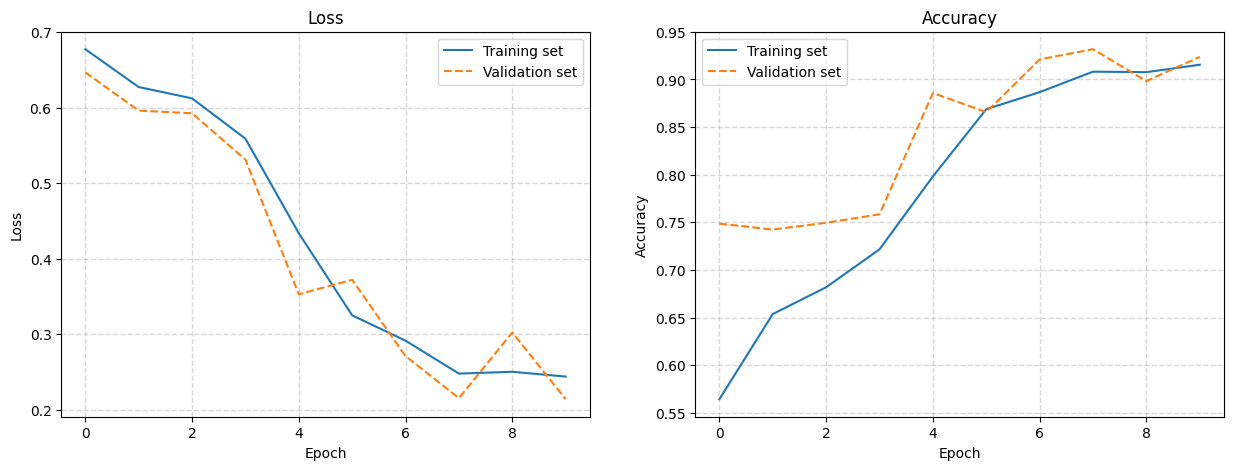

In [32]:
loss = result.history['loss']
val_loss = result.history['val_loss']
acc = result.history['accuracy']
val_acc = result.history['val_accuracy']

plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.plot(loss, label='Training set')
plt.plot(val_loss, label='Validation set', linestyle='--')
plt.legend()
plt.grid(linestyle='--', linewidth=1, alpha=0.5)

plt.subplot(1, 2, 2)
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.plot(acc, label='Training set')
plt.plot(val_acc, label='Validation set', linestyle='--')
plt.legend()
plt.grid(linestyle='--', linewidth=1, alpha=0.5)

plt.show()

In [33]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

Saved artifact at '/tmp/tmpkq5rlgww'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 120, 120, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  139002277625488: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139002161366992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139002161366608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139002161366800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139002161365840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139002161367376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139002161367184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139002161367760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139002161367568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139002161368144: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13900216136641

UJI TESTING

In [ ]:
from google.colab import files
from PIL import Image
import numpy as np
import tensorflow as tf

# Unggah gambar
uploaded = files.upload()

# Proses gambar yang diunggah
image_path = list(uploaded.keys())[0]
image = Image.open(image_path)
image.show()

# Ubah ukuran gambar menjadi (120, 120) sesuai dengan input model
image = image.resize((120, 120))

# Ubah gambar menjadi array dan skalakan nilai pikselnya
image_array = np.array(image) / 255.0

# Tambahkan dimensi untuk batch (1, 120, 120, 3)
image_array = np.expand_dims(image_array, axis=0)

# Konversi array gambar menjadi tipe data FLOAT32
image_array = image_array.astype(np.float32)

# Nama file model TFLite
TFLITE_MODEL = 'model__v1.tflite'

# Memuat model TFLite
interpreter = tf.lite.Interpreter(model_path=TFLITE_MODEL)
interpreter.allocate_tensors()

# Mendapatkan detail input dan output
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print("Model TFLite berhasil dimuat.")

# Menetapkan input tensor
input_index = input_details[0]['index']
interpreter.set_tensor(input_index, image_array)

# Menjalankan inferensi
interpreter.invoke()

# Mendapatkan output tensor
output_index = output_details[0]['index']
output_array = interpreter.get_tensor(output_index)

# Debug: Print raw output
print("Raw output array:", output_array)

# Mendapatkan prediksi
predictions = output_array[0]
print("Predictions:", predictions)
probability = predictions[0]
if probability > 0.5:
    predicted_label = 'Uninfected'
else:
    predicted_label = 'Parasitized'

print(f'Prediksi kelas: {predictions[0]}')
print(f'Label prediksi: {predicted_label}')
print(f'Keyakinan: {probability}')